Accuracy: 0.5031578947368421
Precision: 0.5033871808233454
Recall: 0.5081536033666492
F1 Score: 0.5057591623036649


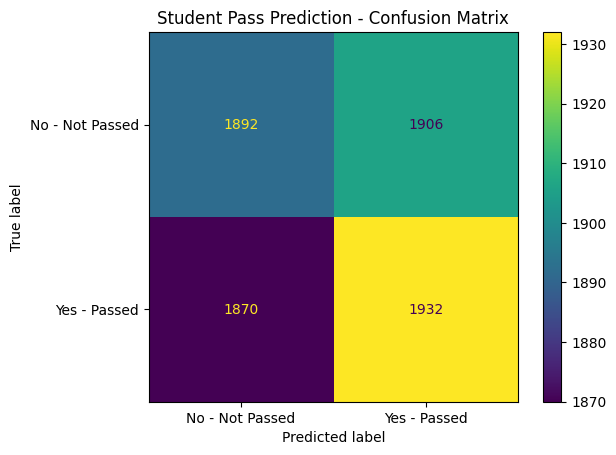

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Load the dataset
data = pd.read_csv(
    "student_performance_prediction.csv"
)

# 2. Remove duplicate rows and rows with a missing target
data = data.drop_duplicates()
data = data.dropna(subset=["Passed"]).copy()

# 3. Separate features (X) and target (y)
X = data.drop(columns=["Passed", "Student ID"])
y = data["Passed"].astype(str).str.strip().str.lower()

# Convert target labels to numbers: No = 0, Yes = 1
y = y.map({"no": 0, "yes": 1})

# Remove any rows with unexpected target labels, if present
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows].astype(int)

# 4. Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 5. Identify numerical and categorical columns
numerical_columns = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# 6. Prepare numerical data
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 7. Prepare categorical data
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# 8. Apply the appropriate preprocessing to each column type
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

# 9. Create the classification model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# 10. Train the model
model.fit(X_train, y_train)

# 11. Predict student results
y_pred = model.predict(X_test)

# 12. Evaluate model performance
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

# 13. Display the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No - Not Passed", "Yes - Passed"]
)

display.plot()
plt.title("Student Pass Prediction - Confusion Matrix")
plt.show()
